# **DSN Bootcamp Qualification Hackathon 2026 — ML Track**
### **Predicting Product-Store Total Sales for DSN Mart**

**Author:** Michael Mabayomije Jinadu

**Approach summary:** This notebook cleans and explores the DSN Mart product-store sales dataset,
engineers a small set of leakage-safe features, and trains a two-model ensemble
(CatBoost + LightGBM, each hyperparameter-tuned with Optuna) to predict `total_sales`
for each product-store combination in the test set. The pipeline below is the exact
process behind the final submission.


## **IMPORTING LIBRARIES**

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import lightgbm as lgb
from catboost import CatBoostRegressor

pd.set_option('display.max_columns', None)  #This will display all columns in the DataFrame when printed


## **LOADING THE GIVEN DATASET**




In [49]:
train_df = pd.read_csv(r"G:\Other computers\My Laptop\Desktop\PYTHON SANDBOX\train.csv")
test_df = pd.read_csv(r"G:\Other computers\My Laptop\Desktop\PYTHON SANDBOX\test.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)


Train shape: (6818, 13)
Test shape: (1705, 12)


In [50]:
train_df.head()

,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
0,row_00000,PRD-PRFP9S,14.252,Low Fat,0.0271,Frozen Foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98
1,row_00001,PRD-PXXK71,7.698,Low Fat,0.0720,HEALTH AND HYGIENE,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13
2,row_00002,PRD-V5MOIJ,14.264,Regular,0.0421,Canned,41.35,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,378.85
3,row_00003,PRD-UN5Z3J,NaN,Regular,0.0449,soft drinks,174.35,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,5595.72
4,row_00004,PRD-6RDQYB,10.338,Regular,0.0120,meat,203.06,STORE-9RG,28,Small,Tier_2,Standard Supermarket,2375.36


In [51]:
test_df.head()

,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format
0,row_00009,PRD-2WLNC8,8.628,Low Fat,0.0167,household,190.72,STORE-HL7,23,Medium,Tier_3,Superstore
1,row_00015,PRD-LV9PLM,6.993,Low Fat,0.0579,Health and Hygiene,261.07,STORE-9RG,28,Small,Tier_2,Standard Supermarket
2,row_00019,PRD-ET6ZI7,NaN,Low Fat,0.1262,FRUITS AND VEGETABLES,112.50,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket
3,row_00020,PRD-6RX35U,14.034,Regular,0.0761,frozen foods,200.71,STORE-DKU,30,NaN,Tier_2,Standard Supermarket
4,row_00023,PRD-I4J38V,13.063,Low Fat,0.0650,Frozen Foods,150.59,STORE-89Z,33,Medium,Tier_1,Standard Supermarket


In [52]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6818 entries, 0 to 6817
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   6818 non-null   object 
 1   product_code         6818 non-null   object 
 2   product_weight_kg    5593 non-null   float64
 3   fat_content          6818 non-null   object 
 4   shelf_visibility     6818 non-null   float64
 5   product_category     6818 non-null   object 
 6   product_price        6818 non-null   float64
 7   store_code           6818 non-null   object 
 8   store_age_years      6818 non-null   int64  
 9   store_size           4899 non-null   object 
 10  store_location_tier  6818 non-null   object 
 11  store_format         6818 non-null   object 
 12  total_sales          6818 non-null   float64
dtypes: float64(4), int64(1), object(8)
memory usage: 692.6+ KB


In [53]:
train_df.describe(include='all')

,id,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales
count,6818,6818,5593.000000,6818,6818.000000,6818,6818.000000,6818,6818.000000,4899,6818,6818,6818.000000
unique,6818,1555,NaN,2,NaN,48,NaN,10,NaN,3,3,4,NaN
top,row_00000,PRD-YZB4K8,NaN,Low Fat,NaN,Fruits and Vegetables,NaN,STORE-YLW,NaN,Medium,Tier_3,Standard Supermarket,NaN
freq,1,9,NaN,4425,NaN,480,NaN,754,NaN,2218,2677,4462,NaN
mean,NaN,NaN,12.850876,NaN,0.065527,NaN,140.473623,NaN,34.178205,NaN,NaN,NaN,2174.756574
std,NaN,NaN,4.646542,NaN,0.051566,NaN,62.413513,NaN,8.384574,NaN,NaN,NaN,1697.894956
min,NaN,NaN,4.482000,NaN,0.000000,NaN,31.110000,NaN,23.000000,NaN,NaN,NaN,32.700000
25%,NaN,NaN,8.750000,NaN,0.026600,NaN,93.280000,NaN,28.000000,NaN,NaN,NaN,834.792500
50%,NaN,NaN,12.647000,NaN,0.053200,NaN,142.065000,NaN,33.000000,NaN,NaN,NaN,1790.890000
75%,NaN,NaN,16.894000,NaN,0.093400,NaN,185.987500,NaN,45.000000,NaN,NaN,NaN,3092.587500


In [54]:
train_df.nunique().sort_values()

fat_content               2
store_size                3
store_location_tier       3
store_format              4
store_age_years           9
store_code               10
product_category         48
product_code           1555
shelf_visibility       1732
product_weight_kg      4675
product_price          5818
total_sales            6776
id                     6818
dtype: int64

## **CHECK ON MISSING AND DUPLICATED VALUES**

In [55]:

print("Duplicate rows:", train_df.duplicated().sum()) #checking for duplicate rows in the training dataset
print()
print("Missing values (train):")
print(train_df.isnull().sum()) #checking for missing values in the training dataset


Duplicate rows: 0

Missing values (train):
id                        0
product_code              0
product_weight_kg      1225
fat_content               0
shelf_visibility          0
product_category          0
product_price             0
store_code                0
store_age_years           0
store_size             1919
store_location_tier       0
store_format              0
total_sales               0
dtype: int64


**Key observations from initial inspection:**
- 6,818 training rows, 1,705 test rows, 12 features + target (`total_sales`).
- `product_weight_kg` and `store_size` have substantial missing values.
- `product_category` and `fat_content` contain inconsistent casing (e.g. `'Dairy'` vs `'dairy'`),
  which inflates their apparent number of unique categories.
- Only 10 unique stores and 1,555 unique products exist — store-level patterns matter a lot.


## **DATA CLEANING**

Cleaning steps, in order:
1. Standardise text casing in `product_category` and `fat_content`.
2. Impute `product_weight_kg` using each product's own historical weight (median), falling back to the
   global median only for products with no recorded weight at all.
3. Impute `store_size` using the most common size for that store's `store_format` — this is safe because,
   apart from `Standard Supermarket`, every format maps to exactly one size in the observed data.
4. Treat `shelf_visibility == 0` as a missing-value placeholder (a product cannot realistically have zero
   shelf visibility) and impute with the per-category median.

All imputation statistics (medians, modes) are learned **only from the training data** and then reused
on the test set, to avoid data leakage.


In [56]:
train_df = train_df.drop(columns=['id']) #dropping the 'id' column as it is not useful for prediction.

# Standardise text casing
train_df['product_category'] = train_df['product_category'].str.strip().str.lower() #balancing the text casing for product_category column
train_df['fat_content'] = train_df['fat_content'].str.strip().str.lower() #balancing the text casing for fat_content column

print(train_df['product_category'].nunique(), "product categories after cleaning") #checking the number of unique values in product_category column
print(train_df['fat_content'].unique()) #checking the unique values in fat_content column


16 product categories after cleaning
['low fat' 'regular']


 **DATA IMPUTATION FOR MISSING VALUES**

In [57]:
# Impute product_weight_kg: per-product median, then global median fallback
product_weight_map = train_df.groupby('product_code')['product_weight_kg'].median() # Create a map of median weights for each product
train_df['product_weight_kg'] = train_df['product_weight_kg'].fillna(train_df['product_code'].map(product_weight_map)) # Fill missing values with per-product medians

global_weight_median = train_df['product_weight_kg'].median() # Calculate the global median
train_df['product_weight_kg'] = train_df['product_weight_kg'].fillna(global_weight_median) # Fill any remaining missing values with the global median


In [58]:
# Impute store_size: mode of size within each store_format
store_size_map = train_df.groupby('store_format')['store_size'].apply( # creating a mapping of store_format to the most common store_size
    lambda x: x.mode()[0] if not x.mode().empty else np.nan # Fill missing values with the most common store_size for each store_format
)
print(store_size_map) # Display the mapping

train_df['store_size'] = train_df.apply( # Fill missing values in store_size column
    lambda row: store_size_map[row['store_format']] if pd.isnull(row['store_size']) else row['store_size'], # Fill missing values with the most common store_size for each store_format
    axis=1
)


store_format
Corner Shop              Small
Flagship Hypermarket    Medium
Standard Supermarket     Small
Superstore              Medium
Name: store_size, dtype: object


In [59]:
# Treat shelf_visibility == 0 as missing, impute with per-category median
train_df['shelf_visibility'] = train_df['shelf_visibility'].replace(0, np.nan)
shelf_vis_map = train_df.groupby('product_category')['shelf_visibility'].median()
train_df['shelf_visibility'] = train_df['shelf_visibility'].fillna(train_df['product_category'].map(shelf_vis_map))

print("Remaining missing values:")
print(train_df.isnull().sum())


Remaining missing values:
product_code           0
product_weight_kg      0
fat_content            0
shelf_visibility       0
product_category       0
product_price          0
store_code             0
store_age_years        0
store_size             0
store_location_tier    0
store_format           0
total_sales            0
dtype: int64


##  **Exploratory Data Analysis**

**Target distribution**
`total_sales` is right-skewed (mean > median), with a long tail of high-value sales.


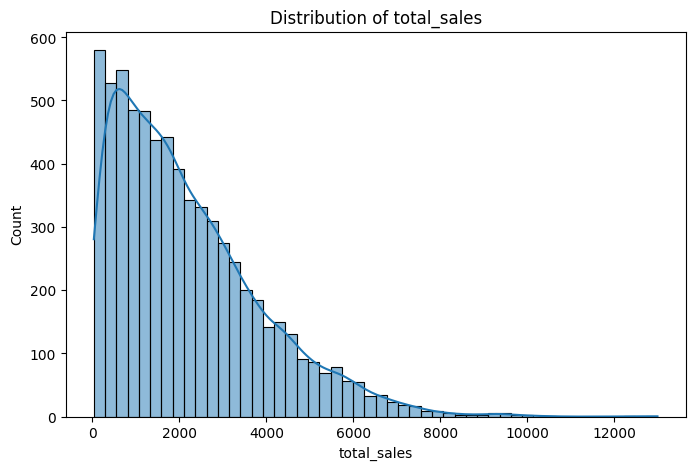

count     6818.000000
mean      2174.756574
std       1697.894956
min         32.700000
25%        834.792500
50%       1790.890000
75%       3092.587500
max      12996.820000
Name: total_sales, dtype: float64


In [60]:
plt.figure(figsize=(8, 5))
sns.histplot(train_df['total_sales'], bins=50, kde=True)
plt.title('Distribution of total_sales')
plt.xlabel('total_sales')
plt.show()

print(train_df['total_sales'].describe())


### **Numeric feature correlations with total_sales**
`product_price` shows the strongest linear relationship with sales (r ≈ 0.57).


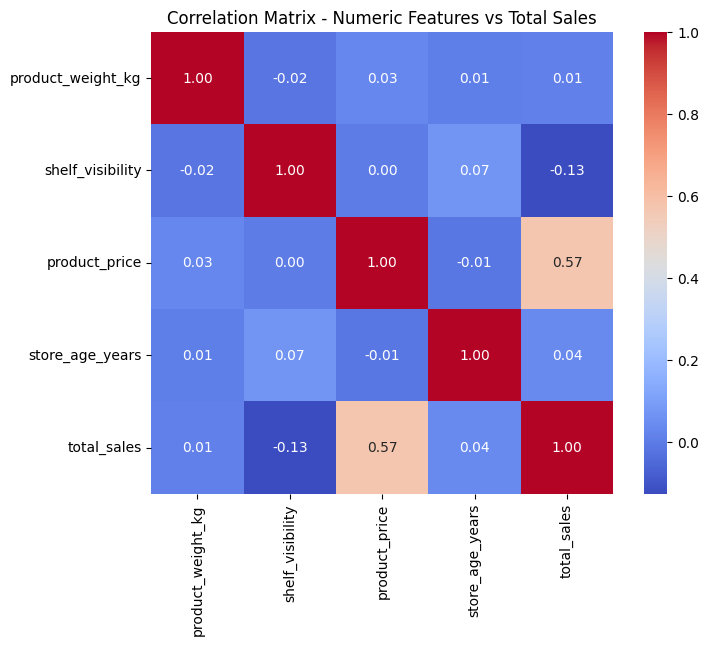

total_sales          1.000000
product_price        0.569833
store_age_years      0.039443
product_weight_kg    0.014135
shelf_visibility    -0.125294
Name: total_sales, dtype: float64


In [61]:
numeric_cols = ['product_weight_kg', 'shelf_visibility', 'product_price', 'store_age_years', 'total_sales']
corr_matrix = train_df[numeric_cols].corr().astype(float)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix.to_numpy(), annot=True, cmap='coolwarm', fmt='.2f', square=True,
            xticklabels=numeric_cols, yticklabels=numeric_cols)
plt.title('Correlation Matrix - Numeric Features vs Total Sales')
plt.show()

print(corr_matrix['total_sales'].sort_values(ascending=False))


### **Categorical factors vs total_sales**
`store_format` shows by far the largest swing in average sales — Flagship Hypermarkets average
~3,660 vs Corner Shops at ~336, roughly a 10x difference. `product_category` shows a milder,
independent effect.


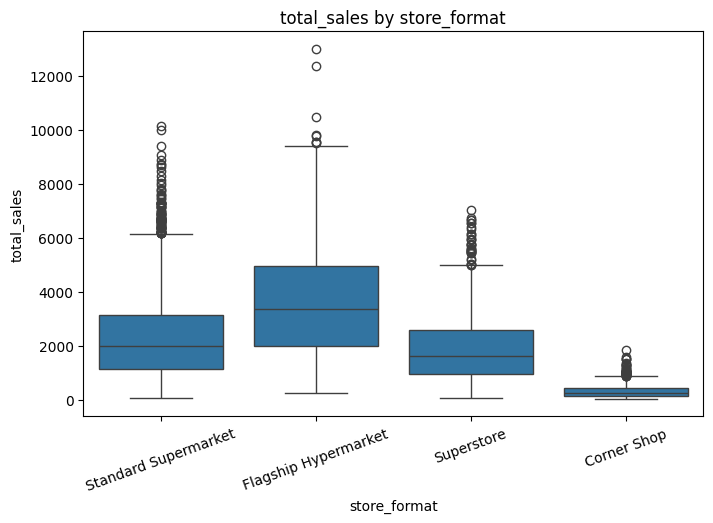

store_format
Flagship Hypermarket    3660.182219
Standard Supermarket    2316.319677
Superstore              1971.661954
Corner Shop              336.353868
Name: total_sales, dtype: float64


In [62]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=train_df, x='store_format', y='total_sales')
plt.title('total_sales by store_format')
plt.xticks(rotation=20)
plt.show()

print(train_df.groupby('store_format', observed=True)['total_sales'].mean().sort_values(ascending=False))


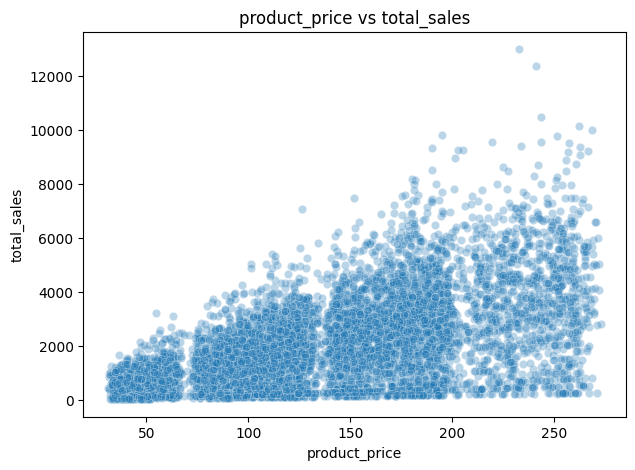

In [63]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=train_df, x='product_price', y='total_sales', alpha=0.3)
plt.title('product_price vs total_sales')
plt.show()


**Store-level and product-price sanity checks**
The two highest-sales rows in the dataset (~12,000-13,000) both occur at Flagship Hypermarkets
with high product prices and low shelf visibility — consistent with, not contradicting, the
patterns found above. These are treated as genuine values, not errors.


## **Feature Engineering**

Two engineered features were added, then verified via ablation testing (systematically removing
each feature and re-measuring cross-validated RMSE) to confirm they add real value:

- `price_per_weight` = price relative to product weight
- `price_vs_category_avg` = how a product's price compares to its own category's average price

A feature-importance-guided selection process (built-in importance + permutation importance) was
then used to narrow down to the 8 features that contribute genuine, non-redundant signal for the
CatBoost model, while LightGBM performed best retaining the full feature set.


In [64]:
train_df['price_per_weight'] = train_df['product_price'] / train_df['product_weight_kg']

category_price_map = train_df.groupby('product_category', observed=True)['product_price'].mean()
train_df['price_vs_category_avg'] = train_df['product_price'] - train_df['product_category'].map(category_price_map)

train_df.head()


,product_code,product_weight_kg,fat_content,shelf_visibility,product_category,product_price,store_code,store_age_years,store_size,store_location_tier,store_format,total_sales,price_per_weight,price_vs_category_avg
0,PRD-PRFP9S,14.252,low fat,0.0271,frozen foods,81.37,STORE-AGY,45,Large,Tier_3,Standard Supermarket,1764.98,5.709374,-56.737941
1,PRD-PXXK71,7.698,low fat,0.0720,health and hygiene,42.05,STORE-YLW,35,Small,Tier_1,Standard Supermarket,342.13,5.462458,-86.752257
2,PRD-V5MOIJ,14.264,regular,0.0421,canned,41.35,STORE-89Z,33,Medium,Tier_1,Standard Supermarket,378.85,2.898906,-96.766228
3,PRD-UN5Z3J,12.665,regular,0.0449,soft drinks,174.35,STORE-7WS,47,Medium,Tier_3,Flagship Hypermarket,5595.72,13.766285,45.259180
4,PRD-6RDQYB,10.338,regular,0.0120,meat,203.06,STORE-9RG,28,Small,Tier_2,Standard Supermarket,2375.36,19.642097,59.587965


### **Apply identical cleaning + feature engineering to the test set (using train-derived lookups only)**

In [65]:
test_df['product_category'] = test_df['product_category'].str.strip().str.lower()
test_df['fat_content'] = test_df['fat_content'].str.strip().str.lower()

test_df['product_weight_kg'] = test_df['product_weight_kg'].fillna(test_df['product_code'].map(product_weight_map))
test_df['product_weight_kg'] = test_df['product_weight_kg'].fillna(global_weight_median)

test_df['store_size'] = test_df.apply(
    lambda row: store_size_map[row['store_format']] if pd.isnull(row['store_size']) else row['store_size'],
    axis=1
)

test_df['shelf_visibility'] = test_df['shelf_visibility'].replace(0, np.nan)
test_df['shelf_visibility'] = test_df['shelf_visibility'].fillna(test_df['product_category'].map(shelf_vis_map))

test_df['price_per_weight'] = test_df['product_price'] / test_df['product_weight_kg']
test_df['price_vs_category_avg'] = test_df['product_price'] - test_df['product_category'].map(category_price_map)

print(set(train_df.columns) - {'total_sales'} - set(test_df.columns))  # should be empty
print(test_df.isnull().sum())


set()
id                       0
product_code             0
product_weight_kg        0
fat_content              0
shelf_visibility         0
product_category         0
product_price            0
store_code               0
store_age_years          0
store_size               0
store_location_tier      0
store_format             0
price_per_weight         0
price_vs_category_avg    0
dtype: int64


In [66]:
categorical_cols = ['fat_content', 'product_category', 'store_size', 'store_location_tier', 'store_format', 'store_code']
for col in categorical_cols:
    train_df[col] = train_df[col].astype('category')
    test_df[col] = test_df[col].astype('category')

feature_cols = [col for col in train_df.columns if col not in ['total_sales', 'product_code']]
top_features = ['product_price', 'price_vs_category_avg', 'store_format', 'store_code',
                'product_weight_kg', 'shelf_visibility', 'price_per_weight', 'product_category']
categorical_cols_top = [c for c in categorical_cols if c in top_features]

X = train_df[feature_cols]           # full feature set -> used by LightGBM
X_top = train_df[top_features]       # reduced feature set -> used by CatBoost
y = train_df['total_sales']

kf = KFold(n_splits=5, shuffle=True, random_state=42)


## **MODEL BUILDING**

Three gradient boosting model families were evaluated (LightGBM, XGBoost, CatBoost), each tuned with
Optuna (Bayesian/TPE hyperparameter search, 50-150 trials). CatBoost and LightGBM performed best and
most consistently; a Random Forest baseline was also tested and clearly underperformed, so it was not
pursued further. Deep learning was ruled out given the dataset size (~6,800 rows).

Final tuned hyperparameters (found via Optuna, reproduced here for the final fit):


In [67]:
lgb_final_params = {
    'num_leaves': 29, 'max_depth': 3, 'learning_rate': 0.028983460765588456,
    'n_estimators': 176, 'min_child_samples': 79, 'subsample': 0.8446208636033256,
    'colsample_bytree': 0.8627902181165324, 'reg_alpha': 5.278122425337818e-08,
    'reg_lambda': 1.4811767615188562, 'random_state': 42, 'verbose': -1
}

cat_final_params = {
    'iterations': 264, 'depth': 5, 'learning_rate': 0.022538791140520528,
    'l2_leaf_reg': 0.21306196734873567, 'random_strength': 1.2791227570360715,
    'bagging_temperature': 0.526700761824265, 'random_state': 42, 'verbose': 0
}


### *Cross-validated ensemble performance*

The final approach: CatBoost trained on the 8-feature set, LightGBM trained on the full feature set,
predictions averaged 50/50. This configuration was validated across 5 different random seeds
(not just one train/validation split) to confirm the result is stable and not an artifact of a
lucky fold arrangement, before being trusted for submission.


In [68]:
rmse_scores = []
for train_idx, val_idx in kf.split(train_df):
    X_train_lgb, X_val_lgb = X.iloc[train_idx], X.iloc[val_idx]
    X_train_cat, X_val_cat = X_top.iloc[train_idx], X_top.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    m_lgb = lgb.LGBMRegressor(**lgb_final_params)
    m_lgb.fit(X_train_lgb, y_train, categorical_feature=categorical_cols)
    p_lgb = m_lgb.predict(X_val_lgb)

    m_cat = CatBoostRegressor(**cat_final_params)
    m_cat.fit(X_train_cat, y_train, cat_features=categorical_cols_top)
    p_cat = m_cat.predict(X_val_cat)

    blend = (p_lgb + p_cat) / 2
    rmse_scores.append(np.sqrt(mean_squared_error(y_val, blend)))

print(f"Cross-validated RMSE: {np.mean(rmse_scores):.2f} (+/- {np.std(rmse_scores):.2f})")


Cross-validated RMSE: 1076.54 (+/- 20.71)


### **FEATURE IMPORTANCE**

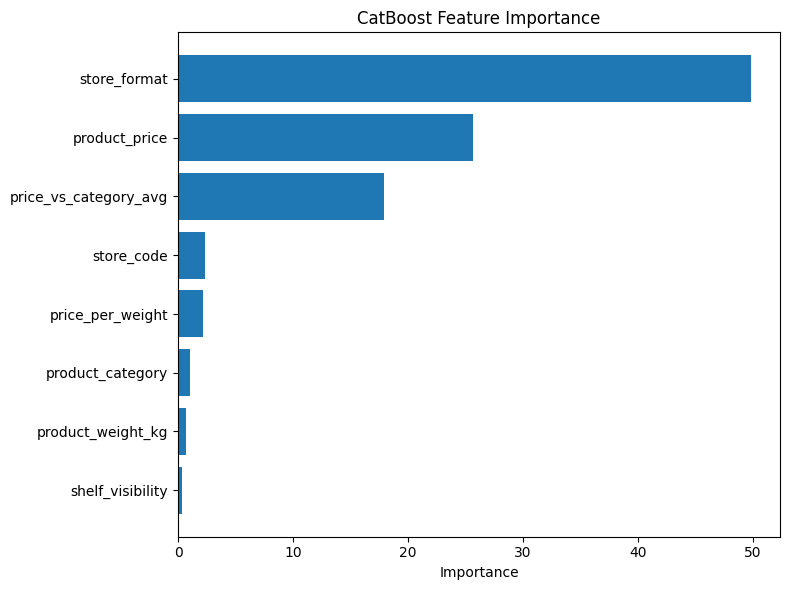

In [69]:
# CatBoost feature importance (built-in)
final_cat_check = CatBoostRegressor(**cat_final_params)
final_cat_check.fit(X_top, y, cat_features=categorical_cols_top)

importance_cat = pd.DataFrame({
    'feature': X_top.columns,
    'importance': final_cat_check.feature_importances_
}).sort_values('importance', ascending=True)

plt.figure(figsize=(8, 6))
plt.barh(importance_cat['feature'], importance_cat['importance'])
plt.xlabel('Importance')
plt.title('CatBoost Feature Importance')
plt.tight_layout()
plt.show()


## **Final Model Training and Prediction**

Both models are retrained on the **full** training set (not just CV folds), then used to predict
`total_sales` for every row in `test.csv`. Final predictions are the simple average of the two
models' outputs.


In [70]:
final_lgb = lgb.LGBMRegressor(**lgb_final_params)
final_lgb.fit(X, y, categorical_feature=categorical_cols)

final_cat = CatBoostRegressor(**cat_final_params)
final_cat.fit(X_top, y, cat_features=categorical_cols_top)

X_test_full = test_df[feature_cols]
X_test_top = test_df[top_features]

preds_lgb = final_lgb.predict(X_test_full)
preds_cat = final_cat.predict(X_test_top)

final_predictions = (preds_lgb + preds_cat) / 2

print(final_predictions[:10])
print(len(final_predictions))


[2797.71053146 4342.02832012 3015.36606356 3118.21808745 2511.20544141
  387.65798454 3978.73309252 3224.94054033  374.4005699  2111.37939033]
1705


## **SUBMISSION FILE**


In [71]:
submission = pd.DataFrame({
    'id': test_df['id'],
    'total_sales': final_predictions
})

print(submission.head(10))
print(submission.shape)

submission.to_csv(r"G:\Other computers\My Laptop\Desktop\PYTHON SANDBOX\submission_final.csv", index=False)
print("Saved.")


          id  total_sales
0  row_00009  2797.710531
1  row_00015  4342.028320
2  row_00019  3015.366064
3  row_00020  3118.218087
4  row_00023  2511.205441
5  row_00026   387.657985
6  row_00027  3978.733093
7  row_00033  3224.940540
8  row_00034   374.400570
9  row_00037  2111.379390
(1705, 2)
Saved.


## **DETAILED SUMMARY OF WORK DONE**

- **Data cleaning:** standardised categorical text, imputed missing values using leakage-safe,
  train-only statistics (per-product weight medians, per-format size modes, per-category
  visibility medians), and treated `shelf_visibility == 0` as a missing-value placeholder.
- **EDA:** identified `store_format` and `product_price` as the dominant drivers of `total_sales`,
  with `product_category` and `store_location_tier` contributing smaller, independent effects.
- **Feature engineering:** two ratio/relative-price features were engineered and validated via
  ablation testing; feature selection (guided by both built-in and permutation importance) found
  an 8-feature subset that improved CatBoost's performance without hurting LightGBM's.
- **Modelling:** compared LightGBM, XGBoost, CatBoost, and Random Forest; tuned the top two
  (LightGBM, CatBoost) with Optuna; validated the final ensemble across multiple random seeds
  before submitting, to guard against overfitting to a single validation split.
- **Result:** cross-validated RMSE of ~1075-1076, translating to a public leaderboard RMSE of
  **1072.09**.
